In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
mercari_full = pd.read_csv("../data/train.tsv", sep="\t")
mercari = mercari_full.sample(n=100_000, random_state=RANDOM_STATE).reset_index(drop=True)
print(mercari.shape)

(100000, 8)


In [2]:
before = len(mercari)
mercari = mercari[mercari["price"] > 0].reset_index(drop=True)
print("Removed rows with price = 0:", before - len(mercari))

mercari["log_price"] = np.log1p(mercari["price"])
print("Shape now:", mercari.shape)

Removed rows with price = 0: 57
Shape now: (99943, 9)


In [3]:
def create_features(df):
    df = df.copy()

    # fill missing values
    df["name"] = df["name"].fillna("").astype(str)
    df["item_description"] = df["item_description"].fillna("").astype(str)
    df["brand_name"] = df["brand_name"].fillna("missing")
    df["category_name"] = df["category_name"].fillna("missing/missing/missing")

    # text length features
    df["name_length"] = df["name"].str.len()
    df["name_word_count"] = df["name"].str.split().str.len()
    df["desc_length"] = df["item_description"].str.len()
    df["desc_word_count"] = df["item_description"].str.split().str.len()

    # description quality flags
    df["no_description"] = (
        (df["item_description"] == "") |
        (df["item_description"] == "No description yet")
    ).astype(int)
    df["rm_count"] = df["item_description"].str.count(r"\[rm\]")   # price removed by Mercari

    # brand flag
    df["has_brand"] = (df["brand_name"] != "missing").astype(int)

    # split category path into 3 levels
    cats = df["category_name"].str.split("/", n=2, expand=True)
    df["cat_main"] = cats[0].fillna("missing")
    df["cat_sub1"] = cats[1].fillna("missing")
    df["cat_sub2"] = cats[2].fillna("missing")

    return df

mercari = create_features(mercari)

In [4]:
display(
    mercari[
        ["name", "name_length", "name_word_count", "desc_length", "desc_word_count",
         "no_description", "rm_count", "has_brand",
         "cat_main", "cat_sub1", "cat_sub2", "price", "log_price"]
    ].head()
)

,name,name_length,name_word_count,desc_length,desc_word_count,no_description,rm_count,has_brand,cat_main,cat_sub1,cat_sub2,price,log_price
0,F/ship 4 Totoro Washi + 1 pen,29,7,158,29,0,0,0,Handmade,Paper Goods,Stationery,12.0,2.564949
1,UCLA Men's Bundle + Shorts,26,5,57,15,0,0,1,Women,Other,Other,76.0,4.343805
2,Listing for lol,15,3,28,5,0,0,0,Beauty,Makeup,Lips,12.0,2.564949
3,25 pcs kawaii sticker flakes,28,5,68,14,0,0,0,Kids,Toys,Arts & Crafts,3.0,1.386294
4,Chanel Mini Lipgloss Set,24,4,53,9,0,0,1,Beauty,Makeup,Lips,30.0,3.433987


In [5]:
mercari.isna().sum()

train_id             0
name                 0
item_condition_id    0
category_name        0
brand_name           0
price                0
shipping             0
item_description     0
log_price            0
name_length          0
name_word_count      0
desc_length          0
desc_word_count      0
no_description       0
rm_count             0
has_brand            0
cat_main             0
cat_sub1             0
cat_sub2             0
dtype: int64

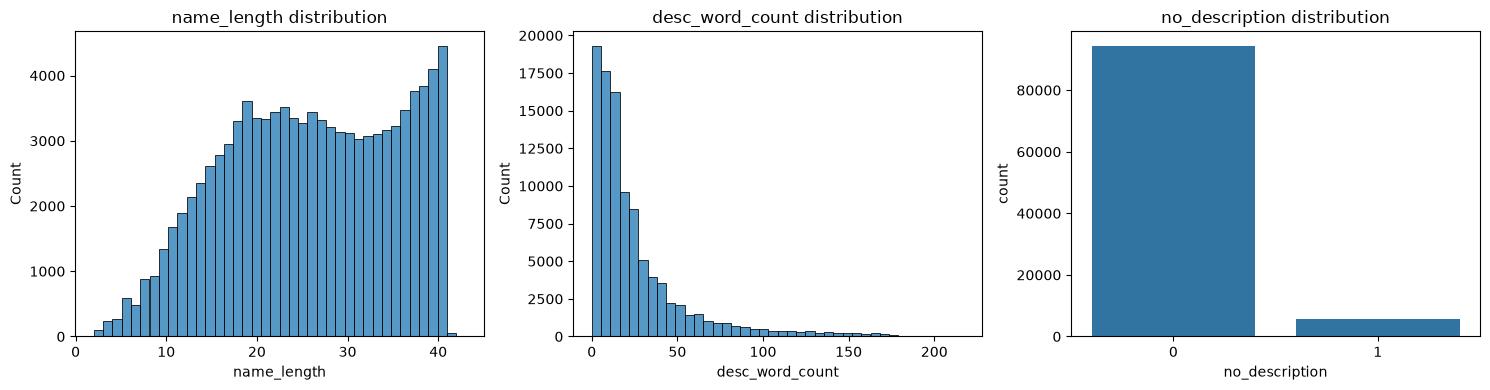

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(mercari["name_length"], bins=40, ax=axes[0])
axes[0].set_title("name_length distribution")

sns.histplot(mercari["desc_word_count"], bins=40, ax=axes[1])
axes[1].set_title("desc_word_count distribution")

sns.countplot(data=mercari, x="no_description", ax=axes[2])
axes[2].set_title("no_description distribution")

plt.tight_layout()
plt.show()

In [7]:
print(mercari.groupby("no_description")["price"].agg(["count", "mean", "median"]))

                count       mean  median
no_description                          
0               94383  27.103287    17.0
1                5560  21.980036    15.0


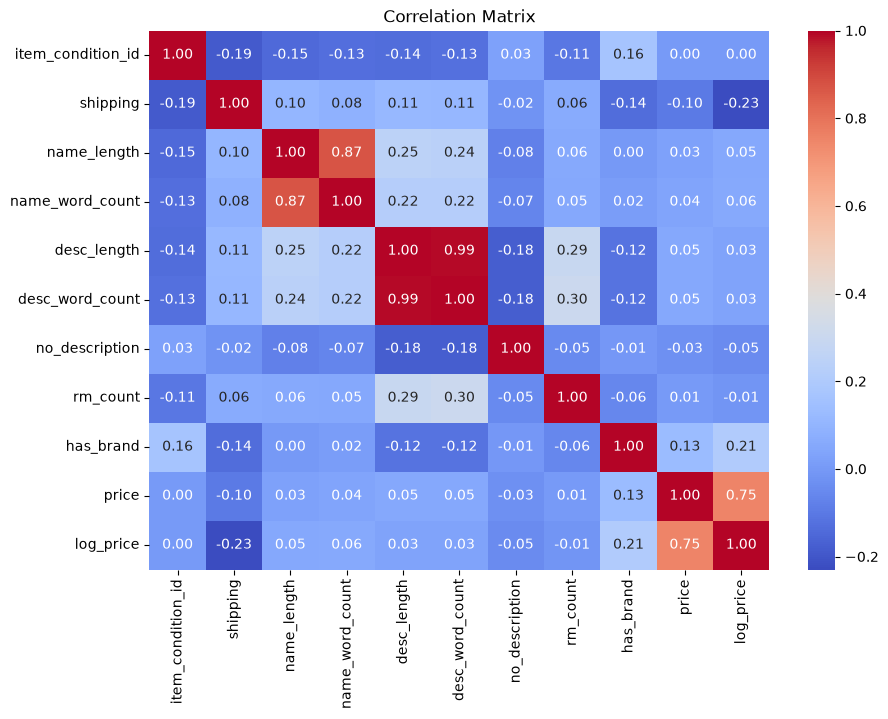

In [8]:
numeric_columns = [
    "item_condition_id", "shipping", "name_length", "name_word_count",
    "desc_length", "desc_word_count", "no_description", "rm_count",
    "has_brand", "price", "log_price"
]

plt.figure(figsize=(10, 7))
sns.heatmap(
    mercari[numeric_columns].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)
plt.title("Correlation Matrix")
plt.show()

**Correlation findings**
- Linear correlation with `log_price` is weak for most numeric features. The strongest
  are `shipping` (-0.23) and `has_brand` (+0.21).
- `name_length` and `name_word_count` are highly correlated (0.87), and so are
  `desc_length` and `desc_word_count` (0.99). They are redundant for linear models
  but harmless for tree models.
- Listings with no description (5,560 rows) have a mean price of about \$22 and a
  median of \$15.
- Brand (1,838 unique values) and sub-category (681 unique values) have many levels,
  so rare levels will be grouped together during encoding.

In [9]:
numeric_features = [
    "item_condition_id", "shipping", "name_length", "name_word_count",
    "desc_length", "desc_word_count", "no_description", "rm_count", "has_brand"
]

categorical_features = ["brand_name", "cat_main", "cat_sub1", "cat_sub2"]

text_name = "name"
text_description = "item_description"

print("Numeric:", len(numeric_features))
print("Categorical:", len(categorical_features))

Numeric: 9
Categorical: 4


In [10]:
from sklearn.model_selection import train_test_split

all_features = numeric_features + categorical_features + [text_name, text_description]

X = mercari[all_features].copy()
y_log = mercari["log_price"].copy()
y_price = mercari["price"].copy()

X_train, X_test, y_train, y_test, y_train_price, y_test_price = train_test_split(
    X,
    y_log,
    y_price,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (79954, 15)
Testing: (19989, 15)


In [11]:
print("Unique brands in train:", X_train["brand_name"].nunique())
print("Unique sub-categories (level 2) in train:", X_train["cat_sub2"].nunique())

Unique brands in train: 1838
Unique sub-categories (level 2) in train: 681


In [12]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.compose import ColumnTransformer

In [13]:
numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("Numerical preprocessing pipeline created.")

Numerical preprocessing pipeline created.


In [14]:
# min_frequency groups rare brands / sub-categories into one "infrequent" column
categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="infrequent_if_exist",
        min_frequency=30
    ))
])

print("Categorical preprocessing pipeline created.")

Categorical preprocessing pipeline created.


In [15]:
tfidf_demo = TfidfVectorizer(
    stop_words="english",
    max_features=20
)

tfidf_matrix_demo = tfidf_demo.fit_transform(X_train["name"])

print("TF-IDF matrix shape:", tfidf_matrix_demo.shape)
print("Example vocabulary:")
print(tfidf_demo.get_feature_names_out()[:20])

TF-IDF matrix shape: (79954, 20)
Example vocabulary:
['black' 'bundle' 'case' 'dress' 'free' 'iphone' 'leggings' 'lularoe'
 'new' 'nike' 'nwt' 'pink' 'secret' 'set' 'shirt' 'shorts' 'size'
 'victoria' 'vs' 'women']


In [16]:
# One TF-IDF per text column, because name and description behave differently
name_tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=3000,
    ngram_range=(1, 2),
    min_df=3
)

description_tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    ngram_range=(1, 2),
    min_df=5
)

print("TF-IDF preprocessors created.")

TF-IDF preprocessors created.


In [17]:
sparse_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_preprocessor, numeric_features),
        ("cat", categorical_preprocessor, categorical_features),
        ("name_text", name_tfidf, text_name),
        ("desc_text", description_tfidf, text_description)
    ],
    remainder="drop"
)

print("Sparse (TF-IDF) preprocessor created.")

Sparse (TF-IDF) preprocessor created.


In [18]:
sparse_preprocessor.fit(X_train)

X_train_sparse = sparse_preprocessor.transform(X_train)
X_test_sparse = sparse_preprocessor.transform(X_test)

print("Train matrix shape:", X_train_sparse.shape)
print("Test matrix shape:", X_test_sparse.shape)
print("Type:", type(X_train_sparse))

Train matrix shape: (79954, 8585)
Test matrix shape: (19989, 8585)
Type: <class 'scipy.sparse._csr.csr_matrix'>


In [19]:
# TruncatedSVD compresses thousands of TF-IDF columns into a small dense set
name_svd_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english", max_features=3000, ngram_range=(1, 2), min_df=3
    )),
    ("svd", TruncatedSVD(n_components=50, random_state=RANDOM_STATE))
])

desc_svd_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english", max_features=5000, ngram_range=(1, 2), min_df=5
    )),
    ("svd", TruncatedSVD(n_components=100, random_state=RANDOM_STATE))
])

svd_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_preprocessor, numeric_features),
        ("cat", categorical_preprocessor, categorical_features),
        ("name_svd", name_svd_pipeline, text_name),
        ("desc_svd", desc_svd_pipeline, text_description)
    ],
    remainder="drop"
)

print("SVD preprocessor created.")

SVD preprocessor created.


In [20]:
svd_preprocessor.fit(X_train)

X_train_svd = svd_preprocessor.transform(X_train)
X_test_svd = svd_preprocessor.transform(X_test)

print("Train matrix shape:", X_train_svd.shape)
print("Test matrix shape:", X_test_svd.shape)

Train matrix shape: (79954, 735)
Test matrix shape: (19989, 735)


In [21]:
name_svd = svd_preprocessor.named_transformers_["name_svd"].named_steps["svd"]
desc_svd = svd_preprocessor.named_transformers_["desc_svd"].named_steps["svd"]

print("Name SVD explained variance:", round(name_svd.explained_variance_ratio_.sum(), 4))
print("Description SVD explained variance:", round(desc_svd.explained_variance_ratio_.sum(), 4))

Name SVD explained variance: 0.1958
Description SVD explained variance: 0.2897


In [22]:
preprocessing_summary = pd.DataFrame({
    "Preprocessor": ["Sparse TF-IDF (linear models)", "TF-IDF + SVD (tree / boosting models)"],
    "Train columns": [X_train_sparse.shape[1], X_train_svd.shape[1]]
})

display(preprocessing_summary)

,Preprocessor,Train columns
0,Sparse TF-IDF (linear models),8585
1,TF-IDF + SVD (tree / boosting models),735


In [23]:
feature_names_svd = svd_preprocessor.get_feature_names_out()
print("Total features:", len(feature_names_svd))
print(feature_names_svd[:15])
print(feature_names_svd[-5:])

Total features: 735
['num__item_condition_id' 'num__shipping' 'num__name_length'
 'num__name_word_count' 'num__desc_length' 'num__desc_word_count'
 'num__no_description' 'num__rm_count' 'num__has_brand'
 'cat__brand_name_ALDO' 'cat__brand_name_ALEX AND ANI'
 'cat__brand_name_Abercrombie & Fitch' 'cat__brand_name_Adidas'
 'cat__brand_name_Aeropostale' 'cat__brand_name_Air Jordan']
['desc_svd__truncatedsvd95' 'desc_svd__truncatedsvd96'
 'desc_svd__truncatedsvd97' 'desc_svd__truncatedsvd98'
 'desc_svd__truncatedsvd99']


## Preprocessing Approach

**Numeric features (9):** median imputation, then StandardScaler.

**Categorical features (4):** most-frequent imputation, then OneHotEncoder.
`min_frequency=30` groups rare brands and sub-categories into one "infrequent"
column, and `handle_unknown="infrequent_if_exist"` lets the pipeline accept
brands it has never seen (important for the deployed app).

**Text features (name, description):** TF-IDF with English stop words and
unigrams + bigrams. Name and description have separate vectorizers.

**Two versions of the preprocessor:**
1. *Sparse TF-IDF* keeps all text columns. Best for linear models such as Ridge.
2. *TF-IDF + TruncatedSVD* compresses text into 50 + 100 dense components.
   Used for Random Forest, XGBoost and LightGBM, which are slow on
   thousands of sparse columns.

All preprocessors are **fit on training data only**, so there is no data leakage.
**Results**
- Sparse TF-IDF preprocessor: 8,585 columns. TF-IDF + SVD preprocessor: 735 columns.
- SVD explained variance: name 19.6% (50 components), description 29.0% (100 components).
- Low explained variance is expected for text. The original brand, category and
  numeric features are kept in full alongside the compressed text.

In [24]:
import os
import joblib
from sklearn.base import clone

os.makedirs("../data/processed", exist_ok=True)
os.makedirs("../models", exist_ok=True)

joblib.dump(
    {
        "X_train": X_train, "X_test": X_test,
        "y_train": y_train, "y_test": y_test,                    # log1p(price)
        "y_train_price": y_train_price, "y_test_price": y_test_price,  # dollars
        "numeric_features": numeric_features,
        "categorical_features": categorical_features,
        "text_name": text_name,
        "text_description": text_description,
        # unfitted copies, so each model fits its own preprocessor
        "sparse_preprocessor": clone(sparse_preprocessor),
        "svd_preprocessor": clone(svd_preprocessor),
    },
    "../data/processed/split_and_preprocessors.joblib"
)
print("Saved.")

Saved.
